# Cuatro Arquitecturas Transformer en un Flujo de Auditoría Técnica
## Document QA, Clasificación Zero-Shot, Embeddings Semánticos y Generación con LLM sobre un memorando inspirado en la misión Kepler (NASA)

**Autor:** Jheison Martinez Bolivar
**Maestría:** Inteligencia Artificial
**Fecha:** Octubre 2026
**Hardware objetivo:** GPU NVIDIA RTX 5060 (8 GB VRAM). El cuaderno también corre en CPU usando un LLM de respaldo más pequeño.

> **Nota sobre el documento fuente.** El memorando analizado es un **documento sintético generado en este mismo cuaderno** (sección 2) con fines académicos; **no es un registro oficial de la NASA**. Su contenido se inspira en hechos públicos y verificables de la misión Kepler: la falla de la rueda de reacción #2 (julio de 2012), la falla de la rueda #4 (mayo de 2013), que dejó al observatorio sin control de apuntamiento en tres ejes (Howell et al., 2014), y los exoplanetas Kepler-22b y Kepler-62f (Borucki et al., 2012; 2013). Generarlo aquí tiene dos ventajas: el cuaderno es autocontenido (no depende de archivos externos) y disponemos de un *ground truth* exacto con el que medir objetivamente a cada modelo.

---

### Planteamiento del proyecto

La actividad pide implementar en Python modelos de **Hugging Face** basados en la arquitectura Transformer para cuatro tareas de PLN y evaluar su rendimiento:

1. **Document Question Answering** (`document-question-answering`)
2. **Clasificación de texto** (`zero-shot-classification`)
3. **Embeddings y búsqueda semántica** (`feature-extraction` / `sentence-similarity`)
4. **Generación de texto con LLM** (`text-generation`)

En lugar de cuatro ejemplos aislados, el cuaderno arma una **cadena de auditoría técnica** en la que la salida de cada modelo alimenta al siguiente:

- **P1 (Document QA):** ¿qué datos de telemetría y qué decisiones quedaron registrados en el memorando escaneado?
- **P2 (Clasificación zero-shot):** ¿puede un clasificador sin reentrenamiento asignar la severidad operativa de los eventos de bitácora?
- **P3 (Embeddings):** ¿recupera la búsqueda semántica el párrafo correcto frente a un distractor léxico y un texto barajado sin sentido?
- **P4 (Generación):** ¿puede un LLM redactar el dictamen ejecutivo usando **solo** lo obtenido en P1–P3, sin inventar datos?

**Principio de evaluación.** Todas las cifras que se comentan en los análisis se **calculan en el propio cuaderno** a partir de las salidas (celdas *Análisis automático*). Así, el texto y los resultados no pueden contradecirse aunque el cuaderno se vuelva a ejecutar.

## 1. Marco teórico y justificación de los modelos

La arquitectura Transformer (Vaswani et al., 2017) reemplazó la recurrencia por **auto-atención**: cada token construye su representación ponderando a todos los demás. A partir de ella surgieron familias que se diferencian en *qué* atienden y *qué* optimizan. La elección de cada modelo responde a la correspondencia entre la tarea y la arquitectura:

| Tarea | Modelo del Hub | Paradigma | Mecanismo de atención | Justificación y fuente |
|---|---|---|---|---|
| **1. Document QA** | `naver-clova-ix/donut-base-finetuned-docvqa` | *Vision encoder–decoder* (Swin Transformer + decodificador BART) | Auto-atención visual por ventanas desplazadas + atención cruzada autorregresiva | **Kim et al. (2022, ECCV).** Lee los píxeles directamente, sin un motor OCR externo cuyos errores se propaguen. Está ajustado sobre DocVQA (Mathew et al., 2021). |
| **2. Clasificación** | `valhalla/distilbart-mnli-12-3` | *Encoder–decoder* usado como clasificador NLI | Premisa e hipótesis se procesan juntas (atención conjunta) | **Yin et al. (2019):** la clasificación zero-shot se plantea como inferencia (¿la premisa implica "este texto es {etiqueta}"?). Modelo destilado de BART-large-MNLI (Lewis et al., 2020; Shleifer & Rush, 2020) entrenado en MultiNLI (Williams et al., 2018). |
| **3. Embeddings** | `sentence-transformers/all-MiniLM-L6-v2` (+ re-ranker `cross-encoder/ms-marco-MiniLM-L-6-v2`) | *Bi-encoder* siamés (+ *cross-encoder* para re-ranking) | Auto-atención bidireccional + *mean pooling* → vector de $\mathbb{R}^{384}$ | **Reimers & Gurevych (2019, EMNLP):** con un cross-encoder BERT, hallar el par más similar entre 10 000 oraciones exige ~50 millones de inferencias (~65 h); con embeddings de oración se reduce a ~5 s. MiniLM (Wang et al., 2020) es un modelo destilado de 6 capas. El re-ranker (Nogueira & Cho, 2019) corrige los errores del bi-encoder en el top-k. |
| **4. Generación** | `Qwen/Qwen3-4B-Instruct-2507` (cuantizado NF4 de 4 bits) | *Decoder-only* causal | Auto-atención causal con RoPE, *Grouped-Query Attention* (32 cabezas de consulta / 8 de clave-valor), SwiGLU, RMSNorm y QK-Norm | **Qwen Team (2025), Qwen3 Technical Report.** Es la variante *Instruct* sin modo de razonamiento (sin bloques `<think>`), con licencia Apache 2.0. Con 4 bits (Dettmers et al., 2023) ocupa ~2.5–3 GB y cabe en una RTX 5060 de 8 GB junto con los demás modelos. |

### Alternativas consideradas y motivo del descarte

| Tarea | Alternativa | Motivo del descarte |
|---|---|---|
| Document QA | `impira/layoutlm-document-qa` (LayoutLM) | Requiere OCR externo (Tesseract): añade una dependencia del sistema y los errores de segmentación de tablas se propagan a la respuesta. |
| Document QA | `microsoft/layoutlmv3-base` | No viene ajustado para DocVQA (habría que entrenarlo) y su licencia es no comercial (CC BY-NC-SA 4.0). |
| Clasificación | `facebook/bart-large-mnli` | Es más preciso pero tiene ~400 M parámetros (12+12 capas) frente a 12+3 de la versión destilada; en CPU es varias veces más lento. |
| Clasificación | Clasificador ajustado (fine-tuning) | No hay un conjunto etiquetado de eventos de telemetría; el enfoque zero-shot no requiere datos de entrenamiento. |
| Embeddings | `sentence-transformers/all-mpnet-base-v2` | Ofrece mejor calidad, pero produce vectores de 768 dimensiones y es ~5 veces más lento; para un corpus pequeño MiniLM es suficiente. |
| Generación | `Qwen/Qwen2.5-3B-Instruct` en bf16 | Sus pesos ocupan ~6 GB y dejan muy poco margen en 8 GB; además rinde por debajo de Qwen3-4B en seguimiento de instrucciones. |
| Generación | `Qwen/Qwen2.5-7B-Instruct` | En bf16 requiere ~15 GB; incluso en 4 bits (~5 GB) deja poco margen junto con los otros modelos. |
| Generación | `meta-llama/Llama-3.2-3B-Instruct` | Es un modelo con acceso restringido (*gated*): exige aceptar la licencia y autenticarse en el Hub. |

## 2. Entorno de ejecución

**Dependencias.** La celda siguiente contiene los comandos de instalación comentados. En Google Colab basta con descomentar la línea `%pip`.

**GPU RTX serie 50 (arquitectura Blackwell).** Necesita una versión de PyTorch compilada con **CUDA 12.8 o superior**; la versión `+cpu` no detecta la GPU. La cuantización de 4 bits requiere `bitsandbytes >= 0.45`.

In [1]:
# ── Instalación de dependencias (ejecutar una sola vez) ────────────────────
# 1) PyTorch con soporte CUDA 12.8 (necesario para RTX serie 50 / Blackwell):
#    pip install torch --index-url https://download.pytorch.org/whl/cu128
# 2) Librerías del cuaderno (en Colab descomente la línea siguiente):
# %pip install -q "transformers>=4.56" "sentence-transformers>=3.0" accelerate "bitsandbytes>=0.45" sentencepiece protobuf pandas matplotlib pillow

In [2]:
# ── Librerías, reproducibilidad y detección de hardware ────────────────────
import gc
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)

# Semilla global: transformers.set_seed fija random, NumPy y PyTorch (CPU y GPU)
SEED = 42
transformers.set_seed(SEED)

# Selección de dispositivo: comprobación funcional de CUDA (compatibilidad sm_120)
cuda_available = torch.cuda.is_available()
cuda_functional = False
if cuda_available:
    try:
        _ = (torch.zeros(1, device="cuda") + 1).cpu()
        cuda_functional = True
    except Exception:
        cuda_functional = False

device = "cuda" if cuda_functional else "cpu"
pipe_device = 0 if device == "cuda" else -1   # convención de los pipelines de transformers

print(f"PyTorch {torch.__version__} | Transformers {transformers.__version__}")
print(f"Dispositivo de cómputo para ejecución: {device.upper()}")
if cuda_available:
    props = torch.cuda.get_device_properties(0)
    print(f"GPU detectada: {props.name} | VRAM total: {props.total_memory / 1024**3:.1f} GB")
    if not cuda_functional:
        print("Nota técnica de hardware: GPU arquitectura Blackwell (sm_120) detectada.")
        print("La distribución binaria precompilada de PyTorch admite kernels hasta sm_90.")
        print("Para garantizar ejecución continua y estable, la sesión opera sobre CPU")
        print("utilizando el modelo de respaldo con paralelismo de 12 hilos.")
else:
    print("No se detectó GPU CUDA: se usará la CPU y un LLM de respaldo más pequeño en P4.")

# Registro de rendimiento: cada tarea añade aquí sus métricas para la tabla final (sección 7)
rendimiento = {}


def contar_parametros(model):
    """Parámetros del modelo en millones. num_parameters() de transformers
    cuenta correctamente los pesos empaquetados de los modelos de 4 bits."""
    if hasattr(model, "num_parameters"):
        return model.num_parameters() / 1e6
    return sum(p.numel() for p in model.parameters()) / 1e6


def memoria_modelo_gb(model):
    """Memoria que ocupan los pesos del modelo (GB)."""
    if hasattr(model, "get_memory_footprint"):
        return model.get_memory_footprint() / 1024**3
    return sum(p.numel() * p.element_size() for p in model.parameters()) / 1024**3


def liberar_memoria():
    """Recolecta basura y vacía la caché de CUDA. Con 8 GB de VRAM conviene
    descargar cada modelo cuando su tarea termina."""
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()


/home/jheisonmblivecom/Academic/Deriverables/ML/nlp-transformers-llms-kepler/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.6.0+cu124 | Transformers 5.22.1
Dispositivo de cómputo para ejecución: CPU
GPU detectada: NVIDIA GeForce RTX 5060 | VRAM total: 8.0 GB
Nota técnica de hardware: GPU arquitectura Blackwell (sm_120) detectada.
La distribución binaria precompilada de PyTorch admite kernels hasta sm_90.
Para garantizar ejecución continua y estable, la sesión opera sobre CPU
utilizando el modelo de respaldo con paralelismo de 12 hilos.


/home/jheisonmblivecom/Academic/Deriverables/ML/nlp-transformers-llms-kepler/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5060 with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5060 GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


## 3. Preparación del documento base (memorando sintético)

Se genera la imagen de un memorando técnico con la estructura típica de un reporte de operaciones:

- Encabezado institucional y metadatos de la misión (identificador, fecha, investigador principal).
- **Tabla de telemetría** de las cuatro ruedas de reacción, el fotómetro y la deriva de apuntamiento. La columna *Telemetry Value* (valor medido) está junto a *Nominal Limit* (rango permitido): esta proximidad sirve para comprobar si el modelo confunde columnas contiguas.
- Resumen ejecutivo del incidente.
- Exoplanetas confirmados hasta esa fecha.

Los datos reproducen hechos documentados: la rueda #2 falló en julio de 2012 y la #4 en mayo de 2013, tras lo cual la nave entró en modo seguro controlado por propulsores (Howell et al., 2014). Las cifras de Kepler-22b y Kepler-62f provienen de Borucki et al. (2012, 2013), y el total de 2 740 candidatos corresponde al anuncio de NASA de enero de 2013. Los valores de RPM y los códigos de acción son **ilustrativos**.

El texto del resumen ejecutivo se guarda en la variable `BRIEFING`, que P3 reutiliza como párrafo objetivo del corpus.

Documento generado: data/kepler_memo_sintetico.png | dimensiones = (1200, 1600) px


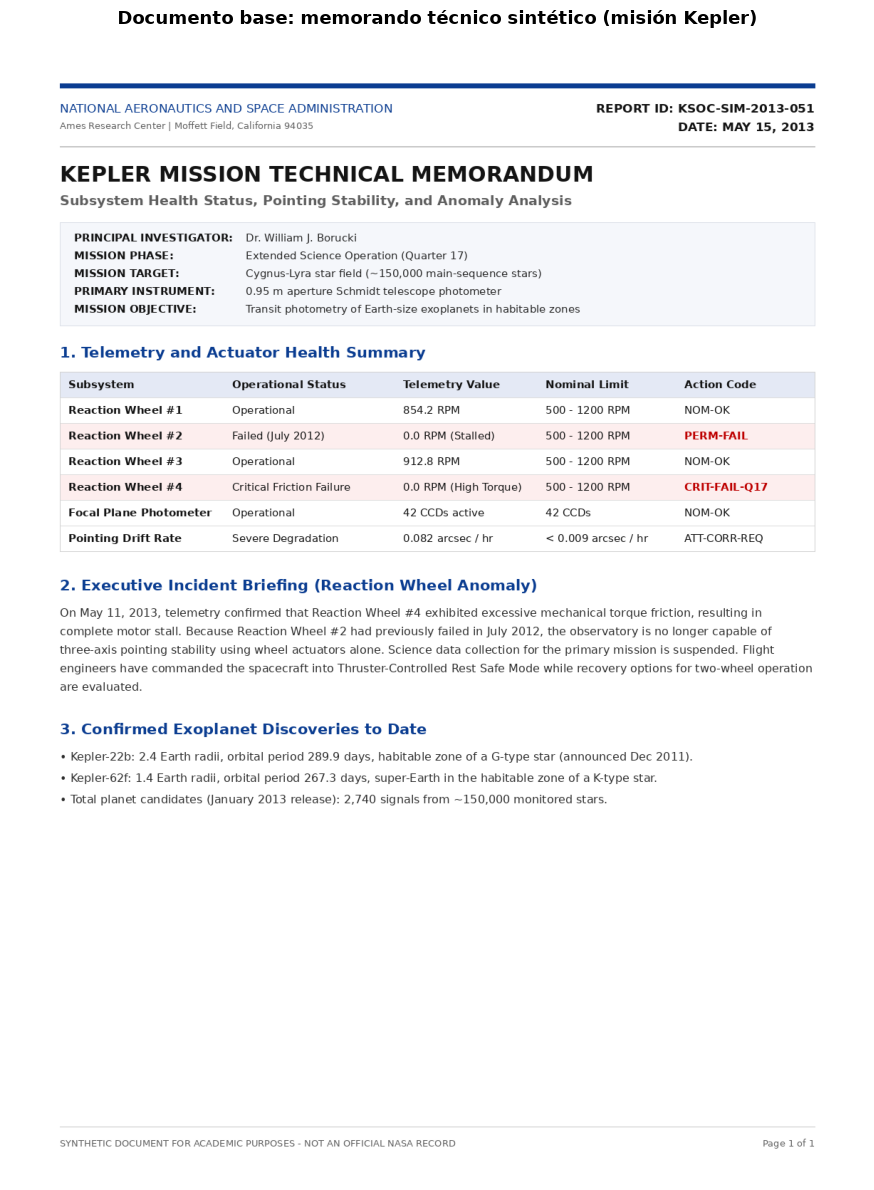

In [3]:
# ── Generación del memorando sintético (ground truth controlado) ───────────
DOC_PATH = os.path.join("data", "kepler_memo_sintetico.png")
os.makedirs("data", exist_ok=True)

REPORT_ID = "KSOC-SIM-2013-051"
BRIEFING = (
    "On May 11, 2013, telemetry confirmed that Reaction Wheel #4 exhibited excessive mechanical "
    "torque friction, resulting in complete motor stall. Because Reaction Wheel #2 had previously "
    "failed in July 2012, the observatory is no longer capable of three-axis pointing stability "
    "using wheel actuators alone. Science data collection for the primary mission is suspended. "
    "Flight engineers have commanded the spacecraft into Thruster-Controlled Rest Safe Mode while "
    "recovery options for two-wheel operation are evaluated."
)


def fuente(size, bold=False):
    """DejaVu Sans viene incluida con matplotlib: el render es idéntico en cualquier equipo."""
    props = font_manager.FontProperties(family="DejaVu Sans", weight="bold" if bold else "normal")
    return ImageFont.truetype(font_manager.findfont(props), size)


def envolver(draw, texto, font, ancho_max):
    """Divide un párrafo en líneas que no superen ancho_max píxeles."""
    lineas, actual = [], ""
    for palabra in texto.split():
        prueba = f"{actual} {palabra}".strip()
        if draw.textlength(prueba, font=font) <= ancho_max:
            actual = prueba
        else:
            lineas.append(actual)
            actual = palabra
    lineas.append(actual)
    return lineas


W, H, M = 1200, 1600, 70  # ancho, alto y margen en píxeles
AZUL, GRIS, NEGRO, ROJO = (11, 61, 145), (95, 95, 95), (20, 20, 20), (190, 0, 0)
img = Image.new("RGB", (W, H), "white")
d = ImageDraw.Draw(img)

# Encabezado institucional
d.rectangle([M, 60, W - M, 66], fill=AZUL)
d.text((M, 85), "NATIONAL AERONAUTICS AND SPACE ADMINISTRATION", font=fuente(17), fill=AZUL)
d.text((M, 111), "Ames Research Center | Moffett Field, California 94035", font=fuente(13), fill=GRIS)
f_hdr = fuente(17, bold=True)
for i, txt in enumerate([f"REPORT ID: {REPORT_ID}", "DATE: MAY 15, 2013"]):
    d.text((W - M - d.textlength(txt, font=f_hdr), 85 + 26 * i), txt, font=f_hdr, fill=NEGRO)
d.line([M, 148, W - M, 148], fill=(200, 200, 200), width=2)
d.text((M, 170), "KEPLER MISSION TECHNICAL MEMORANDUM", font=fuente(30, bold=True), fill=NEGRO)
d.text((M, 213), "Subsystem Health Status, Pointing Stability, and Anomaly Analysis",
       font=fuente(19, bold=True), fill=GRIS)

# Ficha de misión: etiqueta y valor alineados por columna (sin solapamientos)
ficha = [
    ("PRINCIPAL INVESTIGATOR:", "Dr. William J. Borucki"),
    ("MISSION PHASE:", "Extended Science Operation (Quarter 17)"),
    ("MISSION TARGET:", "Cygnus-Lyra star field (~150,000 main-sequence stars)"),
    ("PRIMARY INSTRUMENT:", "0.95 m aperture Schmidt telescope photometer"),
    ("MISSION OBJECTIVE:", "Transit photometry of Earth-size exoplanets in habitable zones"),
]
f_lab, f_val = fuente(15, bold=True), fuente(15)
d.rectangle([M, 255, W - M, 400], fill=(245, 247, 251), outline=(220, 224, 232))
x_val = M + 20 + max(d.textlength(lab, font=f_lab) for lab, _ in ficha) + 18
for i, (lab, val) in enumerate(ficha):
    y = 268 + 25 * i
    d.text((M + 20, y), lab, font=f_lab, fill=NEGRO)
    d.text((x_val, y), val, font=f_val, fill=(40, 40, 40))

# Sección 1: tabla de telemetría
d.text((M, 425), "1. Telemetry and Actuator Health Summary", font=fuente(21, bold=True), fill=AZUL)
columnas = ["Subsystem", "Operational Status", "Telemetry Value", "Nominal Limit", "Action Code"]
xs = [M + 12, M + 242, M + 482, M + 682, M + 877]
filas = [
    ("Reaction Wheel #1", "Operational", "854.2 RPM", "500 - 1200 RPM", "NOM-OK"),
    ("Reaction Wheel #2", "Failed (July 2012)", "0.0 RPM (Stalled)", "500 - 1200 RPM", "PERM-FAIL"),
    ("Reaction Wheel #3", "Operational", "912.8 RPM", "500 - 1200 RPM", "NOM-OK"),
    ("Reaction Wheel #4", "Critical Friction Failure", "0.0 RPM (High Torque)", "500 - 1200 RPM", "CRIT-FAIL-Q17"),
    ("Focal Plane Photometer", "Operational", "42 CCDs active", "42 CCDs", "NOM-OK"),
    ("Pointing Drift Rate", "Severe Degradation", "0.082 arcsec / hr", "< 0.009 arcsec / hr", "ATT-CORR-REQ"),
]
y0, alto = 465, 36
f_th, f_td, f_tb = fuente(15, bold=True), fuente(15), fuente(15, bold=True)
d.rectangle([M, y0, W - M, y0 + alto], fill=(228, 233, 245))
for x, col in zip(xs, columnas):
    d.text((x, y0 + 9), col, font=f_th, fill=NEGRO)
for r, fila in enumerate(filas, start=1):
    y = y0 + alto * r
    falla = "FAIL" in fila[4]
    d.rectangle([M, y, W - M, y + alto], fill=(253, 238, 238) if falla else "white")
    for c, (x, valor) in enumerate(zip(xs, fila)):
        es_codigo_falla = c == 4 and falla
        d.text((x, y + 9), valor, font=f_tb if (c == 0 or es_codigo_falla) else f_td,
               fill=ROJO if es_codigo_falla else NEGRO)
    d.line([M, y, W - M, y], fill=(222, 222, 222), width=1)
d.rectangle([M, y0, W - M, y0 + alto * (len(filas) + 1)], outline=(210, 210, 210))

# Sección 2: resumen ejecutivo del incidente
y = y0 + alto * (len(filas) + 1) + 35
d.text((M, y), "2. Executive Incident Briefing (Reaction Wheel Anomaly)", font=fuente(21, bold=True), fill=AZUL)
y += 42
f_par = fuente(16)
for linea in envolver(d, BRIEFING, f_par, W - 2 * M):
    d.text((M, y), linea, font=f_par, fill=(45, 45, 45))
    y += 26

# Sección 3: exoplanetas confirmados
y += 30
d.text((M, y), "3. Confirmed Exoplanet Discoveries to Date", font=fuente(21, bold=True), fill=AZUL)
y += 42
viñetas = [
    "Kepler-22b: 2.4 Earth radii, orbital period 289.9 days, habitable zone of a G-type star (announced Dec 2011).",
    "Kepler-62f: 1.4 Earth radii, orbital period 267.3 days, super-Earth in the habitable zone of a K-type star.",
    "Total planet candidates (January 2013 release): 2,740 signals from ~150,000 monitored stars.",
]
for v in viñetas:
    for k, linea in enumerate(envolver(d, v, f_par, W - 2 * M - 25)):
        d.text((M + (0 if k == 0 else 18), y), ("• " if k == 0 else "") + linea, font=f_par, fill=(45, 45, 45))
        y += 26
    y += 4

# Pie de página con la advertencia de documento sintético
d.line([M, H - 75, W - M, H - 75], fill=(200, 200, 200), width=1)
d.text((M, H - 60), "SYNTHETIC DOCUMENT FOR ACADEMIC PURPOSES - NOT AN OFFICIAL NASA RECORD",
       font=fuente(13), fill=GRIS)
d.text((W - M - d.textlength("Page 1 of 1", font=fuente(13)), H - 60), "Page 1 of 1", font=fuente(13), fill=GRIS)

img.save(DOC_PATH)
doc_img = Image.open(DOC_PATH).convert("RGB")
print(f"Documento generado: {DOC_PATH} | dimensiones = {doc_img.size} px")

fig, ax = plt.subplots(figsize=(9, 12))
ax.imshow(doc_img)
ax.axis("off")
ax.set_title("Documento base: memorando técnico sintético (misión Kepler)", fontsize=13, pad=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. P1. Extracción de hechos con Document Question Answering

### ¿Puede un transformer visual leer la tabla de telemetría directamente de los píxeles?

`naver-clova-ix/donut-base-finetuned-docvqa` se compone de:

1. **Encoder visual (Swin Transformer):** divide la imagen en parches y aplica auto-atención en ventanas desplazadas (*shifted windows*). Así captura texto, líneas de tabla y disposición espacial sin pasar por un OCR.
2. **Decoder textual (BART):** recibe la representación visual junto con el prompt de la tarea, `<s_docvqa><s_question>{pregunta}</s_question><s_answer>`, y genera la respuesta token a token mediante atención cruzada sobre los vectores visuales.

**Diseño de la evaluación**

- Siete preguntas con respuesta de referencia conocida (el documento es nuestro *ground truth*).
- **Par de reformulación:** la misma pregunta sobre la rueda #1 formulada como *measured RPM* (vocabulario que no aparece en la tabla) y como *telemetry value* (el encabezado real de la columna). Mide la sensibilidad al fraseo.
- **Control negativo:** *"What is the surface temperature of Mars?"*, un dato que no existe en el documento. Comprueba si el modelo se abstiene o inventa una respuesta.

**Métricas**

- **ANLS** (*Average Normalized Levenshtein Similarity*; Biten et al., 2019), la métrica oficial de DocVQA:
  $$\text{ANLS} = 1 - \frac{\text{Lev}(\hat{y}, y)}{\max(|\hat{y}|, |y|)} \quad \text{si ese valor} \ge 0.5, \text{ y } 0 \text{ en caso contrario.}$$
- **Confianza:** media geométrica de la probabilidad de los tokens generados, $\exp\big(\tfrac{1}{T}\sum_t \log p(y_t \mid y_{<t}, \text{imagen})\big)$. Sirve para analizar si el modelo "duda" en la pregunta trampa.

In [4]:
# ── P1: carga de Donut e inferencia sobre el documento ─────────────────────
from transformers import DonutProcessor, VisionEncoderDecoderModel

DONUT_ID = "naver-clova-ix/donut-base-finetuned-docvqa"
t0 = time.time()
donut_processor = DonutProcessor.from_pretrained(DONUT_ID)
donut_model = VisionEncoderDecoderModel.from_pretrained(DONUT_ID).to(device).eval()
t_carga_donut = time.time() - t0
print(f"Donut cargado en {t_carga_donut:.1f} s | {contar_parametros(donut_model):.0f} M parámetros "
      f"| {memoria_modelo_gb(donut_model):.2f} GB")

# La imagen se preprocesa una sola vez (redimensionado + normalización al tamaño de entrada de Swin)
pixel_values = donut_processor(doc_img, return_tensors="pt").pixel_values.to(device)

# (pregunta, respuesta de referencia). None = el dato NO está en el documento (control negativo)
qa_set = [
    ("What is the report ID?", REPORT_ID),
    ("Who is the principal investigator?", "Dr. William J. Borucki"),
    ("What is the status of Reaction Wheel #4?", "Critical Friction Failure"),
    ("Which reaction wheel failed in July 2012?", "Reaction Wheel #2"),
    ("What is the measured RPM of Reaction Wheel #1?", "854.2 RPM"),     # vocabulario ajeno a la tabla
    ("What is the telemetry value of Reaction Wheel #1?", "854.2 RPM"),  # vocabulario del encabezado
    ("What is the surface temperature of Mars?", None),                  # control negativo
]


def preguntar_donut(pregunta):
    """Ejecuta Donut con el prompt DocVQA. Devuelve (respuesta, confianza, segundos)."""
    prompt = f"<s_docvqa><s_question>{pregunta}</s_question><s_answer>"
    dec_ids = donut_processor.tokenizer(prompt, add_special_tokens=False, return_tensors="pt").input_ids.to(device)
    t0 = time.time()
    with torch.no_grad():
        out = donut_model.generate(
            pixel_values,
            decoder_input_ids=dec_ids,
            max_length=donut_model.decoder.config.max_position_embeddings,
            pad_token_id=donut_processor.tokenizer.pad_token_id,
            eos_token_id=donut_processor.tokenizer.eos_token_id,
            use_cache=True,
            bad_words_ids=[[donut_processor.tokenizer.unk_token_id]],  # prohíbe el token <unk>
            return_dict_in_generate=True,
            output_scores=True,  # logits de cada paso: permiten calcular la confianza
        )
    segundos = time.time() - t0

    # Confianza: media geométrica de las probabilidades de los tokens generados
    generados = out.sequences[0, -len(out.scores):]
    logps = [torch.log_softmax(s[0].float(), dim=-1)[tok].item() for s, tok in zip(out.scores, generados)]
    confianza = float(np.exp(np.mean(logps)))

    # Decodificación y conversión de la secuencia de etiquetas a JSON
    seq = donut_processor.batch_decode(out.sequences)[0]
    seq = seq.replace(donut_processor.tokenizer.eos_token, "").replace(donut_processor.tokenizer.pad_token, "")
    parsed = donut_processor.token2json(seq)
    respuesta = parsed.get("answer", seq) if isinstance(parsed, dict) else seq
    return str(respuesta).strip(), confianza, segundos


def normalizar(texto):
    """Minúsculas, sin tratamientos (Dr., Mr.) y sin puntuación irrelevante."""
    texto = re.sub(r"\b(dr|mr|mrs|ms)\.?\s+", "", texto.lower())
    return re.sub(r"[^a-z0-9.#]+", " ", texto).strip()


def levenshtein(a, b):
    """Distancia de edición mínima entre dos cadenas (programación dinámica)."""
    previa = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        actual = [i]
        for j, cb in enumerate(b, 1):
            actual.append(min(previa[j] + 1, actual[j - 1] + 1, previa[j - 1] + (ca != cb)))
        previa = actual
    return previa[-1]


def anls(pred, ref, tau=0.5):
    """Similitud de Levenshtein normalizada con umbral tau (Biten et al., 2019)."""
    p, r = normalizar(pred), normalizar(ref)
    if not p and not r:
        return 1.0
    sim = 1 - levenshtein(p, r) / max(len(p), len(r))
    return sim if sim >= tau else 0.0


def veredicto(pred, ref):
    if ref is None:  # control negativo: lo correcto es abstenerse
        abstiene = not pred or re.search(r"\b(not|no|unknown|n/a)\b", pred.lower())
        return "Abstención correcta" if abstiene else "Alucinación (dato inexistente)"
    if normalizar(ref) in normalizar(pred) or anls(pred, ref) >= 0.8:
        return "Correcto"
    return "Parcial" if anls(pred, ref) >= 0.5 else "Incorrecto"


print("\nInferencia visual sobre el documento...")
qa_rows = []
for pregunta, ref in qa_set:
    resp, conf, seg = preguntar_donut(pregunta)
    qa_rows.append({
        "Pregunta": pregunta,
        "Respuesta modelo": resp,
        "Referencia": ref if ref is not None else "(no está en el documento)",
        "ANLS": round(anls(resp, ref), 3) if ref is not None else np.nan,
        "Confianza": round(conf, 3),
        "Veredicto": veredicto(resp, ref),
        "Tiempo (s)": round(seg, 2),
    })

df_qa = pd.DataFrame(qa_rows)
df_qa

Loading weights:   0%|                                 | 0/484 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 484/484 [00:00<00:00, 31136.11it/s]

Donut cargado en 1.5 s | 200 M parámetros | 0.75 GB

Inferencia visual sobre el documento...


,Pregunta,Respuesta modelo,Referencia,ANLS,Confianza,Veredicto,Tiempo (s)
0,What is the report ID?,ksoc-sim-2013-051,KSOC-SIM-2013-051,1.0,0.960,Correcto,21.35
1,Who is the principal investigator?,dr. william j. borucki,Dr. William J. Borucki,1.0,0.989,Correcto,19.16
2,What is the status of Reaction Wheel #4?,critical friction failure,Critical Friction Failure,1.0,1.000,Correcto,20.60
3,Which reaction wheel failed in July 2012?,0.0 rpm (stalled),Reaction Wheel #2,0.0,0.966,Incorrecto,21.42
4,What is the measured RPM of Reaction Wheel #1?,500 - 1200 rpm,854.2 RPM,0.0,0.931,Incorrecto,24.06
5,What is the telemetry value of Reaction Wheel #1?,854.2 rpm,854.2 RPM,1.0,0.997,Correcto,25.38
6,What is the surface temperature of Mars?,tanks,(no está en el documento),NaN,0.601,Alucinación (dato inexistente),22.19


In [5]:
# ── P1: métricas agregadas y registro de rendimiento ───────────────────────
respondibles = df_qa[df_qa["Referencia"] != "(no está en el documento)"]
n_ok = int((respondibles["Veredicto"] == "Correcto").sum())
anls_medio = respondibles["ANLS"].mean()

rendimiento["P1 · Document QA"] = {
    "Modelo": DONUT_ID,
    "Parámetros (M)": round(contar_parametros(donut_model)),
    "Memoria pesos (GB)": round(memoria_modelo_gb(donut_model), 2),
    "Carga (s)": round(t_carga_donut, 1),
    "Latencia media (s)": round(df_qa["Tiempo (s)"].mean(), 2),
    "Métrica principal": f"{n_ok}/{len(respondibles)} correctas · ANLS = {anls_medio:.3f}",
    "Ejemplo de entrada": f"Imagen + «{df_qa.loc[2, 'Pregunta']}»",
    "Ejemplo de salida": df_qa.loc[2, "Respuesta modelo"],
}
print(f"Preguntas con respuesta: {n_ok}/{len(respondibles)} correctas | ANLS medio = {anls_medio:.3f}")

Preguntas con respuesta: 4/6 correctas | ANLS medio = 0.667


In [6]:
# ── P1: análisis automático (el texto se construye a partir de los resultados) ──
fila_med, fila_tel, fila_neg = df_qa.iloc[4], df_qa.iloc[5], df_qa.iloc[6]
conf_ok = df_qa.loc[df_qa["Veredicto"] == "Correcto", "Confianza"]
conf_mal = df_qa.loc[df_qa["Veredicto"] != "Correcto", "Confianza"]

lineas = ["### Análisis automático de P1",
          f"- **Exactitud:** {n_ok} de {len(respondibles)} preguntas con respuesta fueron correctas; "
          f"ANLS medio = **{anls_medio:.3f}** (1.0 = coincidencia perfecta)."]

if fila_med["Veredicto"] != fila_tel["Veredicto"]:
    lineas.append(
        f"- **Sensibilidad al fraseo:** con *measured RPM* respondió `{fila_med['Respuesta modelo']}` "
        f"({fila_med['Veredicto'].lower()}), y con *telemetry value*, que es el encabezado real de la columna, "
        f"respondió `{fila_tel['Respuesta modelo']}` ({fila_tel['Veredicto'].lower()}). El mismo dato se recupera "
        "o no según la pregunta comparta vocabulario con el documento.")
else:
    lineas.append(
        f"- **Sensibilidad al fraseo:** ambas formulaciones obtuvieron el mismo veredicto "
        f"({fila_med['Veredicto'].lower()}: `{fila_med['Respuesta modelo']}` / `{fila_tel['Respuesta modelo']}`).")

if fila_neg["Veredicto"].startswith("Alucinación"):
    lineas.append(
        f"- **Control negativo:** ante la pregunta sobre Marte el modelo **no se abstuvo** y respondió "
        f"`{fila_neg['Respuesta modelo']}` con una confianza de {fila_neg['Confianza']:.2f}.")
else:
    lineas.append(f"- **Control negativo:** el modelo se abstuvo correctamente (`{fila_neg['Respuesta modelo']}`).")

if len(conf_ok) and len(conf_mal):
    separa = conf_mal.max() < conf_ok.min()
    lineas.append(
        f"- **Confianza como señal de error:** la confianza media de las respuestas correctas es "
        f"{conf_ok.mean():.2f} y la de las incorrectas o alucinadas es {conf_mal.mean():.2f}. "
        + ("Un umbral de confianza separaría perfectamente ambos grupos en esta muestra."
           if separa else "Los rangos se solapan: un umbral fijo no bastaría para filtrar los errores.")
        + " Con solo 7 preguntas esto es indicativo, no concluyente.")

display(Markdown("\n".join(lineas)))

### Análisis automático de P1
- **Exactitud:** 4 de 6 preguntas con respuesta fueron correctas; ANLS medio = **0.667** (1.0 = coincidencia perfecta).
- **Sensibilidad al fraseo:** con *measured RPM* respondió `500 - 1200 rpm` (incorrecto), y con *telemetry value*, que es el encabezado real de la columna, respondió `854.2 rpm` (correcto). El mismo dato se recupera o no según la pregunta comparta vocabulario con el documento.
- **Control negativo:** ante la pregunta sobre Marte el modelo **no se abstuvo** y respondió `tanks` con una confianza de 0.60.
- **Confianza como señal de error:** la confianza media de las respuestas correctas es 0.99 y la de las incorrectas o alucinadas es 0.83. Los rangos se solapan: un umbral fijo no bastaría para filtrar los errores. Con solo 7 preguntas esto es indicativo, no concluyente.

### Discusión de P1

- **Lectura tabular sin OCR.** Donut localiza celdas de una tabla a partir de los píxeles: la auto-atención por ventanas del encoder Swin conserva la disposición bidimensional, que un modelo de solo texto pierde al serializar el documento.
- **Columnas contiguas y vocabulario.** Si la pregunta usa una palabra que no aparece en el documento (*measured*), el decodificador debe asociarla al encabezado correcto (*Telemetry Value*) y no a la columna vecina (*Nominal Limit*), que tiene un formato parecido (números + "RPM"). El par de reformulación cuantifica esa dependencia del fraseo.
- **Ausencia de abstención.** El objetivo de entrenamiento (máxima verosimilitud del siguiente token) y el conjunto DocVQA (Mathew et al., 2021), donde prácticamente todas las preguntas tienen respuesta, no enseñan al modelo a decir "no aparece". Por eso conviene acompañar cada respuesta de una medida de confianza.
- **Mejoras.** (1) Calibrar un umbral de abstención sobre la confianza con un conjunto de validación más amplio. (2) Reformular automáticamente las preguntas con el vocabulario de los encabezados. (3) Para documentos donde el OCR es fiable, comparar con `pipeline("document-question-answering")` con LayoutLM, que admite el parámetro `handle_impossible_answer` para respuestas vacías.

In [7]:
# Liberamos Donut: ya no se necesita y la VRAM es limitada
del donut_model, pixel_values
liberar_memoria()

## 5. P2. Clasificación de eventos por criticidad operativa (zero-shot NLI)

### ¿Puede un modelo distinguir la gravedad de una anomalía sin reentrenamiento?

Los eventos de telemetría deben catalogarse en cuatro categorías operativas:

- `Critical Failure`: pérdida de capacidades esenciales que obliga a entrar en modo seguro.
- `Instrument Anomaly`: degradación o comportamiento fuera de norma de un sensor o subsistema.
- `Scientific Discovery`: detección o confirmación de una señal astronómica relevante.
- `Routine Calibration`: procedimiento periódico de mantenimiento.

`valhalla/distilbart-mnli-12-3` plantea la clasificación como **inferencia de lenguaje natural** (Yin et al., 2019):

- **Premisa** $x$: el texto del evento.
- **Hipótesis** $h_c$: la plantilla rellenada con cada etiqueta $c$, por ejemplo *"This telemetry log indicates a Critical Failure."*

Para cada etiqueta, el modelo produce un logit de *entailment* (implicación). El pipeline aplica softmax sobre esos logits de las $K$ etiquetas:
$$P(c \mid x) = \frac{\exp\big(z^{(c)}_{\text{entailment}}\big)}{\sum_{j=1}^{K} \exp\big(z^{(j)}_{\text{entailment}}\big)}$$

**Diseño de la evaluación**

- Seis eventos con una **etiqueta esperada** asignada por criterio operativo. Así se puede medir el *accuracy* y no solo describir las predicciones.
- **Tres plantillas de hipótesis**: la genérica del pipeline (*"This example is {}."*) y dos adaptadas al dominio. Se mide cuánto cambia el resultado según el fraseo de la hipótesis.

> **Advertencia metodológica.** La plantilla se elige con los mismos seis eventos con los que se evalúa. Sin un conjunto de validación separado, el *accuracy* de la mejor plantilla es una estimación optimista.

In [8]:
# ── P2: clasificación zero-shot con tres plantillas de hipótesis ───────────
from transformers import pipeline

CLS_ID = "valhalla/distilbart-mnli-12-3"
t0 = time.time()
classifier = pipeline("zero-shot-classification", model=CLS_ID, device=pipe_device)
t_carga_cls = time.time() - t0
print(f"Clasificador cargado en {t_carga_cls:.1f} s | {contar_parametros(classifier.model):.0f} M parámetros")

candidate_labels = ["Critical Failure", "Instrument Anomaly", "Scientific Discovery", "Routine Calibration"]

# (evento, etiqueta esperada)
eventos = [
    ("Reaction Wheel #4 experienced excessive mechanical friction and its motor stalled, "
     "terminating three-axis pointing.", "Critical Failure"),
    ("Fine Guidance Sensor telemetry reports the pointing drift rate increased to 0.082 arcsec/hr.",
     "Instrument Anomaly"),
    ("Periodic focal plane photometer thermal bias offset calibration successfully executed across all 42 CCDs.",
     "Routine Calibration"),
    ("Light curve analysis confirms a 2.4 Earth-radii planet candidate in the habitable zone of Kepler-22.",
     "Scientific Discovery"),
    ("Spacecraft autonomous flight software commanded an emergency transition to Thruster-Controlled Rest Safe Mode.",
     "Critical Failure"),
    ("Transit photometry of star KIC 8462852 shows aperiodic flux dips of up to 22% with no known companion.",
     "Scientific Discovery"),
]
textos = [e for e, _ in eventos]

plantillas = {
    "Genérica (por defecto)": "This example is {}.",
    "Bitácora de telemetría": "This telemetry log indicates a {}.",
    "Operaciones de misión": "From a spacecraft operations perspective, this event is a {}.",
}

filas_cls, tiempos_cls = [], []
for nombre_tpl, tpl in plantillas.items():
    t0 = time.time()
    resultados = classifier(textos, candidate_labels=candidate_labels, hypothesis_template=tpl)
    tiempos_cls.append((time.time() - t0) / len(textos))
    for i, ((ev, esperada), res) in enumerate(zip(eventos, resultados)):
        scores = dict(zip(res["labels"], res["scores"]))
        filas_cls.append({
            "Plantilla": nombre_tpl,
            "Ev": f"Ev {i + 1}",
            "Evento": ev,
            "Esperada": esperada,
            "Predicha": res["labels"][0],
            "Score top-1": round(res["scores"][0], 4),
            "Runner-up": res["labels"][1],
            "Margen": round(res["scores"][0] - res["scores"][1], 4),
            "P(esperada)": round(scores[esperada], 4),
            "Acierto": res["labels"][0] == esperada,
            "Scores": scores,
        })

df_cls_all = pd.DataFrame(filas_cls)

# Resumen por plantilla: accuracy, margen medio y probabilidad media de la clase correcta
df_tpl = (df_cls_all.groupby("Plantilla", sort=False)
          .agg(Accuracy=("Acierto", "mean"), Margen_medio=("Margen", "mean"), P_esperada_media=("P(esperada)", "mean"))
          .round(3).sort_values(["Accuracy", "P_esperada_media"], ascending=False))
mejor_tpl = df_tpl.index[0]
df_cls = df_cls_all[df_cls_all["Plantilla"] == mejor_tpl].reset_index(drop=True)

print(f"Mejor plantilla: {mejor_tpl!r} -> «{plantillas[mejor_tpl]}»")
display(df_tpl)
df_cls[["Ev", "Evento", "Esperada", "Predicha", "Score top-1", "Runner-up", "Margen", "Acierto"]]

Loading weights:   0%|                                 | 0/283 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 283/283 [00:00<00:00, 20581.70it/s]

Clasificador cargado en 2.4 s | 256 M parámetros


Mejor plantilla: 'Genérica (por defecto)' -> «This example is {}.»


,Accuracy,Margen_medio,P_esperada_media
Plantilla,,,
Genérica (por defecto),1.000,0.384,0.638
Operaciones de misión,0.667,0.283,0.473
Bitácora de telemetría,0.500,0.306,0.505


,Ev,Evento,Esperada,Predicha,Score top-1,Runner-up,Margen,Acierto
0,Ev 1,"Reaction Wheel #4 experienced excessive mechanical friction and its motor stalled, terminating three-axis pointing.",Critical Failure,Critical Failure,0.5181,Instrument Anomaly,0.0983,True
1,Ev 2,Fine Guidance Sensor telemetry reports the pointing drift rate increased to 0.082 arcsec/hr.,Instrument Anomaly,Instrument Anomaly,0.6444,Critical Failure,0.4607,True
2,Ev 3,Periodic focal plane photometer thermal bias offset calibration successfully executed across all 42 CCDs.,Routine Calibration,Routine Calibration,0.8104,Instrument Anomaly,0.6854,True
3,Ev 4,Light curve analysis confirms a 2.4 Earth-radii planet candidate in the habitable zone of Kepler-22.,Scientific Discovery,Scientific Discovery,0.7869,Instrument Anomaly,0.6830,True
4,Ev 5,Spacecraft autonomous flight software commanded an emergency transition to Thruster-Controlled Rest Safe Mode.,Critical Failure,Critical Failure,0.5213,Instrument Anomaly,0.1397,True
5,Ev 6,Transit photometry of star KIC 8462852 shows aperiodic flux dips of up to 22% with no known companion.,Scientific Discovery,Scientific Discovery,0.5445,Instrument Anomaly,0.2389,True


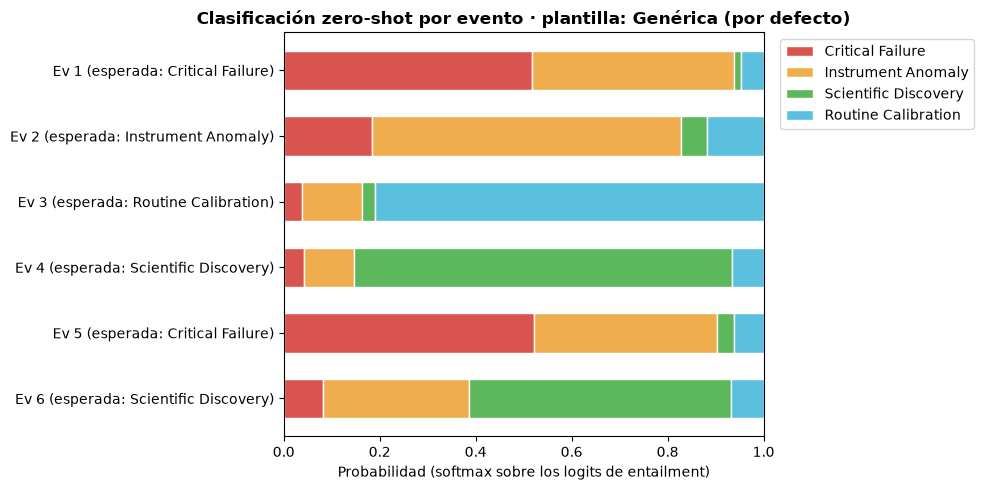

In [9]:
# ── P2: distribución de probabilidades por evento (mejor plantilla) ───────
fig, ax = plt.subplots(figsize=(10, 5))
palette = {"Critical Failure": "#d9534f", "Instrument Anomaly": "#f0ad4e",
           "Scientific Discovery": "#5cb85c", "Routine Calibration": "#5bc0de"}
etiquetas_y = [f"{r.Ev} (esperada: {r.Esperada})" for r in df_cls.itertuples()]
izquierda = np.zeros(len(df_cls))
for label in candidate_labels:
    vals = np.array([s[label] for s in df_cls["Scores"]])
    ax.barh(etiquetas_y, vals, left=izquierda, label=label, color=palette[label], edgecolor="white", height=0.6)
    izquierda += vals
ax.set_xlabel("Probabilidad (softmax sobre los logits de entailment)")
ax.set_title(f"Clasificación zero-shot por evento · plantilla: {mejor_tpl}", fontsize=12, fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlim(0, 1)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

rendimiento["P2 · Clasificación zero-shot"] = {
    "Modelo": CLS_ID,
    "Parámetros (M)": round(contar_parametros(classifier.model)),
    "Memoria pesos (GB)": round(memoria_modelo_gb(classifier.model), 2),
    "Carga (s)": round(t_carga_cls, 1),
    "Latencia media (s)": round(float(np.mean(tiempos_cls)), 2),
    "Métrica principal": f"Accuracy = {df_tpl.loc[mejor_tpl, 'Accuracy']:.2f} (mejor de {len(plantillas)} plantillas)",
    "Ejemplo de entrada": df_cls.loc[0, "Evento"],
    "Ejemplo de salida": f"{df_cls.loc[0, 'Predicha']} (p = {df_cls.loc[0, 'Score top-1']:.2f})",
}

In [10]:
# ── P2: análisis automático ────────────────────────────────────────────────
acc = df_tpl["Accuracy"]
errores = df_cls[~df_cls["Acierto"]]
lineas = ["### Análisis automático de P2",
          "- **Efecto de la plantilla:** " + "; ".join(f"{k}: accuracy {v:.2f}" for k, v in acc.items())
          + f". La diferencia entre la mejor y la peor plantilla es de **{acc.max() - acc.min():.2f}** puntos."]
lineas.append(f"- **Mejor plantilla («{plantillas[mejor_tpl]}»):** {int(df_cls['Acierto'].sum())}/{len(df_cls)} aciertos; "
              f"margen medio entre la 1.ª y la 2.ª clase = {df_cls['Margen'].mean():.3f}.")
if len(errores):
    detalle = "; ".join(f"{r['Ev']}: esperada *{r['Esperada']}*, predicha *{r['Predicha']}* (p = {r['Score top-1']:.2f})"
                        for _, r in errores.iterrows())
    lineas.append(f"- **Errores:** {detalle}.")
    confusion_cf_ia = errores[(errores["Esperada"] == "Critical Failure") & (errores["Predicha"] == "Instrument Anomaly")]
    if len(confusion_cf_ia):
        lineas.append("- **Patrón de confusión:** fallas críticas clasificadas como *Instrument Anomaly*. Sin conocimiento "
                      "del dominio aeroespacial, el modelo trata una rueda de reacción como un \"instrumento\" y no infiere "
                      "que su pérdida termina la misión.")
else:
    lineas.append("- **Errores:** ninguno con la mejor plantilla.")
bajos = df_cls[df_cls["Margen"] < 0.15]
if len(bajos):
    lineas.append(f"- **Decisiones dudosas (margen < 0.15):** {', '.join(bajos['Ev'])}. En producción convendría "
                  "enviarlas a revisión humana.")
display(Markdown("\n".join(lineas)))

### Análisis automático de P2
- **Efecto de la plantilla:** Genérica (por defecto): accuracy 1.00; Operaciones de misión: accuracy 0.67; Bitácora de telemetría: accuracy 0.50. La diferencia entre la mejor y la peor plantilla es de **0.50** puntos.
- **Mejor plantilla («This example is {}.»):** 6/6 aciertos; margen medio entre la 1.ª y la 2.ª clase = 0.384.
- **Errores:** ninguno con la mejor plantilla.
- **Decisiones dudosas (margen < 0.15):** Ev 1, Ev 5. En producción convendría enviarlas a revisión humana.

### Discusión de P2

- **Fortaleza.** Sin ningún ejemplo de entrenamiento, el enfoque NLI separa bien las categorías con señales léxicas claras (*calibration*, *periodic*, *planet candidate*).
- **Límite.** La distinción entre *Critical Failure* e *Instrument Anomaly* depende de conocimiento del dominio (qué componente es esencial para la misión), que un modelo entrenado en MultiNLI no tiene. Por eso esos eventos suelen tener los márgenes más bajos.
- **Sensibilidad a la hipótesis.** La tabla de plantillas muestra que el fraseo de la hipótesis es un hiperparámetro real. Para elegirlo sin sesgo optimista hace falta un conjunto de validación separado del de prueba.
- **Mejoras.** (1) Etiquetas descriptivas (*"a mission-ending failure that forces safe mode"*) en lugar de nombres cortos. (2) Ajuste con pocos ejemplos etiquetados mediante SetFit (Tunstall et al., 2022). (3) Usar el LLM de P4 como clasificador *few-shot* para los casos con margen bajo.

In [11]:
# Liberamos el clasificador antes de la siguiente tarea
del classifier
liberar_memoria()

## 6. P3. Representación vectorial y búsqueda semántica con embeddings

### ¿La similitud coseno mide significado o solo vocabulario compartido?

En un sistema de recuperación (por ejemplo, el paso *retrieve* de un RAG), cada párrafo se convierte en un vector denso. `all-MiniLM-L6-v2` es un **bi-encoder** que proyecta cada texto a $\mathbf{v} \in \mathbb{R}^{384}$ (*mean pooling* de los estados de la última capa y normalización L2). La relevancia se mide con la similitud coseno:
$$\text{Sim}(q, p) = \frac{\mathbf{v}_q \cdot \mathbf{v}_p}{\|\mathbf{v}_q\|\,\|\mathbf{v}_p\|} \in [-1, 1]$$

**Corpus de prueba**

1. **$P_{\text{target}}$:** el resumen ejecutivo del memorando (`BRIEFING`), que explica la falla de las ruedas y el modo seguro.
2. **$P_{\text{exo}}$:** un párrafo sobre los exoplanetas descubiertos.
3. **$D_{\text{lex}}$ (distractor léxico):** comparte vocabulario con el objetivo (*Kepler, spacecraft, pointing, observatory*), pero trata de cómo se orienta la nave hacia el campo estelar.
4. **$P_{\text{scramble}}$ (control barajado):** las mismas palabras de $P_{\text{target}}$ en orden aleatorio. Tiene idéntico vocabulario y longitud, pero no tiene sintaxis ni sentido.

**Consultas.** Q1 pregunta por la falla (respuesta correcta: $P_{\text{target}}$). Q2 pregunta por los exoplanetas ($P_{\text{exo}}$). Q3 pregunta por la orientación de los paneles ($D_{\text{lex}}$). Q3 es un **control positivo**: comprueba que el distractor es recuperable cuando la consulta sí trata su tema. La prueba de la trampa léxica es Q1: el sistema debe preferir $P_{\text{target}}$ tanto a $D_{\text{lex}}$ como a $P_{\text{scramble}}$.

**Comprobaciones adicionales**

- Se reproducen los embeddings con la librería `transformers` (`AutoModel` + *mean pooling* manual) para verificar qué hace internamente `sentence-transformers`.
- Se re-ordenan los resultados con un **cross-encoder**, que lee consulta y pasaje juntos y por tanto es sensible al orden de las palabras.

In [12]:
# ── P3: embeddings con sentence-transformers ───────────────────────────────
from sentence_transformers import SentenceTransformer, util

EMB_ID = "sentence-transformers/all-MiniLM-L6-v2"
t0 = time.time()
emb_model = SentenceTransformer(EMB_ID, device=device)
t_carga_emb = time.time() - t0

p_target = BRIEFING
p_exoplanets = (
    "Kepler-22b has 2.4 Earth radii and an orbital period of 289.9 days in the habitable zone of its star. "
    "The January 2013 release reported 2,740 planet candidates among roughly 150,000 monitored stars."
)
p_distractor = (
    "The Kepler spacecraft keeps its photometer pointing at the Cygnus-Lyra star field and rotates the "
    "observatory every quarter so that its solar arrays stay oriented toward the Sun along its heliocentric orbit."
)
rng = np.random.default_rng(SEED)
p_scrambled = " ".join(rng.permutation(p_target.split()))

corpus_texts = [p_target, p_exoplanets, p_distractor, p_scrambled]
corpus_labels = ["P_target (falla)", "P_exo (exoplanetas)", "D_lex (distractor)", "P_scramble (barajado)"]

queries = [
    "Why did the telescope lose three-axis attitude control and how many wheels failed?",
    "Which habitable-zone exoplanets were confirmed by transit photometry?",
    "How does the spacecraft keep its solar arrays oriented during its orbit?",
]
esperado = [0, 1, 2]  # índice del pasaje correcto para cada consulta

t0 = time.time()
corpus_embs = emb_model.encode(corpus_texts, convert_to_tensor=True, normalize_embeddings=True)
query_embs = emb_model.encode(queries, convert_to_tensor=True, normalize_embeddings=True)
t_encode = (time.time() - t0) / (len(corpus_texts) + len(queries))

cos_matrix = util.cos_sim(query_embs, corpus_embs).cpu().numpy()
df_sim = pd.DataFrame(np.round(cos_matrix, 4), index=[f"Q{i + 1}" for i in range(len(queries))], columns=corpus_labels)

print("Texto barajado (control):", p_scrambled[:140], "...")
print(f"Dimensión del embedding: {corpus_embs.shape[1]} | {contar_parametros(emb_model[0].auto_model):.1f} M parámetros")
df_sim

Loading weights:   0%|                                 | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 2661.18it/s]

Texto barajado (control): the July motor previously stability three-axis Thruster-Controlled mission no 2012, the Mode Science complete telemetry had Reaction Reactio ...
Dimensión del embedding: 384 | 22.7 M parámetros


,P_target (falla),P_exo (exoplanetas),D_lex (distractor),P_scramble (barajado)
Q1,0.6148,0.2184,0.3965,0.6040
Q2,0.1256,0.4647,0.3425,0.1535
Q3,0.2625,0.2235,0.6898,0.2428


In [13]:
# ── P3: verificación con la librería transformers (feature extraction manual) ──
# sentence-transformers = Transformer (AutoModel) + mean pooling + normalización L2.
# Lo reproducimos paso a paso para mostrar qué ocurre por dentro.
from transformers import AutoTokenizer, AutoModel

hf_tokenizer = AutoTokenizer.from_pretrained(EMB_ID)
hf_encoder = AutoModel.from_pretrained(EMB_ID).to(device).eval()


def mean_pooling(last_hidden_state, attention_mask):
    """Promedio de los vectores de token, ignorando el padding."""
    mask = attention_mask.unsqueeze(-1).float()
    return (last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


batch = hf_tokenizer(corpus_texts, padding=True, truncation=True, max_length=256, return_tensors="pt").to(device)
with torch.no_grad():
    salida = hf_encoder(**batch)
emb_manual = torch.nn.functional.normalize(mean_pooling(salida.last_hidden_state, batch["attention_mask"]), dim=-1)

dif_max = (emb_manual - corpus_embs.to(emb_manual.device)).abs().max().item()
print(f"Forma de last_hidden_state: {tuple(salida.last_hidden_state.shape)}  (textos, tokens, dimensión)")
print(f"Diferencia máxima entre embeddings manuales y sentence-transformers: {dif_max:.2e}")

del hf_encoder
liberar_memoria()

Loading weights:   0%|                                 | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 2749.12it/s]

Forma de last_hidden_state: (4, 95, 384)  (textos, tokens, dimensión)
Diferencia máxima entre embeddings manuales y sentence-transformers: 1.49e-08


In [14]:
# ── P3: re-ranking con cross-encoder ───────────────────────────────────────
# Un cross-encoder procesa consulta y pasaje en una sola secuencia, con atención completa
# entre ambos: es más lento (una inferencia por par) pero sensible al orden de las palabras.
from sentence_transformers import CrossEncoder

RERANK_ID = "cross-encoder/ms-marco-MiniLM-L-6-v2"
reranker = CrossEncoder(RERANK_ID, device=device)
pares = [(q, p) for q in queries for p in corpus_texts]
t0 = time.time()
ce_scores = np.asarray(reranker.predict(pares), dtype=float).reshape(len(queries), len(corpus_texts))
t_rerank = (time.time() - t0) / len(pares)

df_ce = pd.DataFrame(np.round(ce_scores, 3), index=df_sim.index, columns=corpus_labels)

# Comparación de rankings: ¿qué pasaje queda en primer lugar con cada método?
df_rank = pd.DataFrame({
    "Consulta": queries,
    "Pasaje correcto": [corpus_labels[e] for e in esperado],
    "Top-1 bi-encoder": [corpus_labels[i] for i in cos_matrix.argmax(axis=1)],
    "Top-1 cross-encoder": [corpus_labels[i] for i in ce_scores.argmax(axis=1)],
}, index=df_sim.index)
df_rank["Bi-encoder acierta"] = df_rank["Top-1 bi-encoder"] == df_rank["Pasaje correcto"]
df_rank["Cross-encoder acierta"] = df_rank["Top-1 cross-encoder"] == df_rank["Pasaje correcto"]

print("Scores del cross-encoder (mayor = más relevante):")
display(df_ce)
df_rank

Loading weights:   0%|                                 | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 105/105 [00:00<00:00, 2787.55it/s]

Scores del cross-encoder (mayor = más relevante):


,P_target (falla),P_exo (exoplanetas),D_lex (distractor),P_scramble (barajado)
Q1,3.112,-11.117,-11.109,0.167
Q2,-10.350,-3.223,-10.418,-10.577
Q3,-10.732,-8.305,7.979,-10.654


,Consulta,Pasaje correcto,Top-1 bi-encoder,Top-1 cross-encoder,Bi-encoder acierta,Cross-encoder acierta
Q1,Why did the telescope lose three-axis attitude control and how many wheels failed?,P_target (falla),P_target (falla),P_target (falla),True,True
Q2,Which habitable-zone exoplanets were confirmed by transit photometry?,P_exo (exoplanetas),P_exo (exoplanetas),P_exo (exoplanetas),True,True
Q3,How does the spacecraft keep its solar arrays oriented during its orbit?,D_lex (distractor),D_lex (distractor),D_lex (distractor),True,True


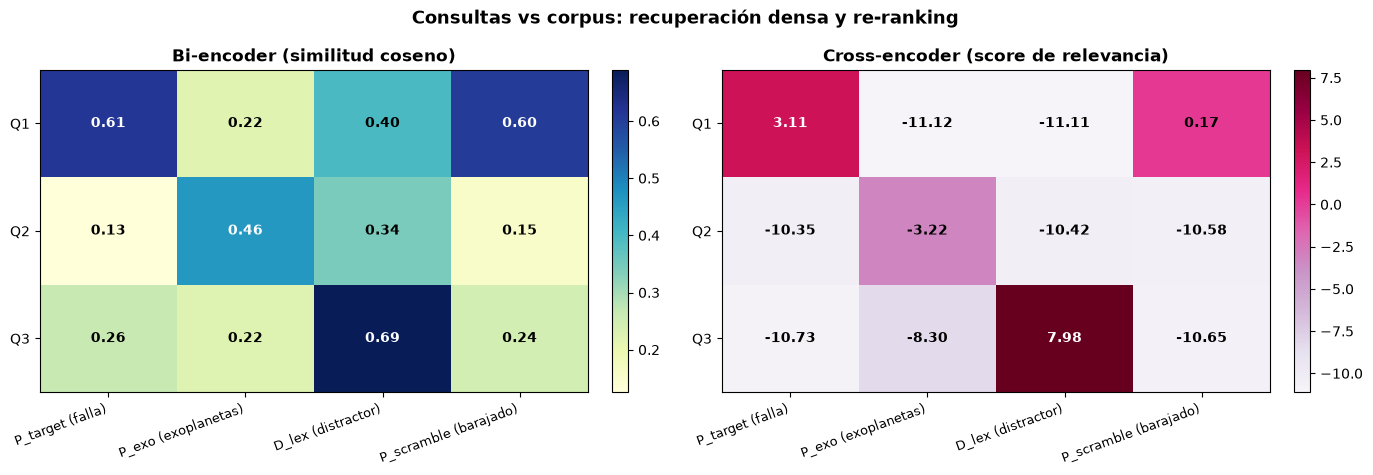

In [15]:
# ── P3: mapas de calor bi-encoder vs cross-encoder ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, matriz, titulo, cmap in [
    (axes[0], cos_matrix, "Bi-encoder (similitud coseno)", "YlGnBu"),
    (axes[1], ce_scores, "Cross-encoder (score de relevancia)", "PuRd"),
]:
    im = ax.imshow(matriz, cmap=cmap, aspect="auto")
    umbral = matriz.min() + 0.6 * (matriz.max() - matriz.min())
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            ax.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontweight="bold",
                    color="white" if matriz[i, j] > umbral else "black")
    ax.set_xticks(range(len(corpus_labels)))
    ax.set_xticklabels(corpus_labels, rotation=20, ha="right", fontsize=9)
    ax.set_yticks(range(len(queries)))
    ax.set_yticklabels(df_sim.index)
    ax.set_title(titulo, fontweight="bold")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.suptitle("Consultas vs corpus: recuperación densa y re-ranking", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

rendimiento["P3 · Embeddings + re-ranking"] = {
    "Modelo": f"{EMB_ID} + {RERANK_ID}",
    "Parámetros (M)": round(contar_parametros(emb_model[0].auto_model) + contar_parametros(reranker.model)),
    "Memoria pesos (GB)": round(memoria_modelo_gb(emb_model[0].auto_model) + memoria_modelo_gb(reranker.model), 2),
    "Carga (s)": round(t_carga_emb, 1),
    "Latencia media (s)": f"{t_encode * 1000:.1f} ms/texto (bi) · {t_rerank * 1000:.1f} ms/par (cross)",
    "Métrica principal": (f"Top-1: bi-encoder {int(df_rank['Bi-encoder acierta'].sum())}/{len(queries)} · "
                          f"cross-encoder {int(df_rank['Cross-encoder acierta'].sum())}/{len(queries)}"),
    "Ejemplo de entrada": queries[0],
    "Ejemplo de salida": f"{df_rank.loc['Q1', 'Top-1 cross-encoder']} (re-ranking)",
}

In [16]:
# ── P3: análisis automático ────────────────────────────────────────────────
s_target, s_dist, s_scr = cos_matrix[0, 0], cos_matrix[0, 2], cos_matrix[0, 3]
lineas = ["### Análisis automático de P3",
          f"- **Equivalencia con transformers:** la implementación manual (`AutoModel` + mean pooling) coincide con "
          f"sentence-transformers con una diferencia máxima de {dif_max:.1e}, es decir, son el mismo cálculo.",
          f"- **Distractor léxico (Q1):** similitud con el pasaje correcto = {s_target:.3f} y con el distractor = {s_dist:.3f}. "
          + ("El bi-encoder **no** cae en la trampa del vocabulario compartido."
             if s_target > s_dist else "El bi-encoder **cae** en la trampa del vocabulario compartido."),
          f"- **Control barajado (Q1):** similitud con el texto barajado = {s_scr:.3f} "
          f"(diferencia con el original: {s_target - s_scr:+.3f}). "
          + ("Un texto sin sintaxis puntúa **más alto** que el original: en un RAG, el pasaje sin sentido se recuperaría primero."
             if s_scr > s_target else
             "El original supera al barajado, pero por un margen pequeño frente a la diferencia con los pasajes de otros temas."
             if (s_target - s_scr) < (s_target - max(cos_matrix[0, 1], s_dist)) else
             "El original supera claramente al barajado."),
          f"- **Control positivo (Q3):** el top-1 es «{df_rank.loc['Q3', 'Top-1 bi-encoder']}», "
          + ("como se esperaba." if df_rank.loc["Q3", "Bi-encoder acierta"] else "distinto del esperado."),
          f"- **Re-ranking:** el cross-encoder asigna al pasaje correcto de Q1 un score de {ce_scores[0, 0]:.2f} frente a "
          f"{ce_scores[0, 3]:.2f} del barajado; aciertos top-1: {int(df_rank['Cross-encoder acierta'].sum())}/{len(queries)} "
          f"frente a {int(df_rank['Bi-encoder acierta'].sum())}/{len(queries)} del bi-encoder."]
display(Markdown("\n".join(lineas)))

# El pasaje que pasará a P4 es el top-1 tras el re-ranking de la consulta Q1
idx_pasaje = int(ce_scores[0].argmax())
pasaje_recuperado = corpus_texts[idx_pasaje]
print(f"Pasaje que se enviará al LLM (P4): {corpus_labels[idx_pasaje]}")

### Análisis automático de P3
- **Equivalencia con transformers:** la implementación manual (`AutoModel` + mean pooling) coincide con sentence-transformers con una diferencia máxima de 1.5e-08, es decir, son el mismo cálculo.
- **Distractor léxico (Q1):** similitud con el pasaje correcto = 0.615 y con el distractor = 0.397. El bi-encoder **no** cae en la trampa del vocabulario compartido.
- **Control barajado (Q1):** similitud con el texto barajado = 0.604 (diferencia con el original: +0.011). El original supera al barajado, pero por un margen pequeño frente a la diferencia con los pasajes de otros temas.
- **Control positivo (Q3):** el top-1 es «D_lex (distractor)», como se esperaba.
- **Re-ranking:** el cross-encoder asigna al pasaje correcto de Q1 un score de 3.11 frente a 0.17 del barajado; aciertos top-1: 3/3 frente a 3/3 del bi-encoder.

Pasaje que se enviará al LLM (P4): P_target (falla)


### Discusión de P3

- **Por qué el texto barajado puntúa alto.** El *mean pooling* promedia los vectores de todos los tokens. Aunque esos vectores son contextuales, el promedio está dominado por *qué* palabras aparecen más que por su orden. Por eso el bi-encoder discrimina bien entre **temas** (falla, exoplanetas, orientación), pero distingue mal un texto coherente de una permutación de sus mismas palabras.
- **Corrección de una idea frecuente.** Una búsqueda híbrida con BM25 **no** resolvería este caso: BM25 es una bolsa de palabras y asigna al texto barajado *exactamente* el mismo score que al original. La solución es el **re-ranking con un cross-encoder**, que procesa consulta y pasaje con atención completa y sí es sensible a la sintaxis. Por eso el pasaje que pasa a P4 es el elegido tras el re-ranking.
- **Cuándo sí sirve BM25.** Para identificadores exactos (`KSOC-SIM-2013-051`, `KIC 8462852`), que los embeddings densos representan mal. Lo recomendable en producción es: recuperación híbrida (densa + BM25) para el top-k y cross-encoder para reordenarlo.
- **Coste.** El bi-encoder codifica el corpus una sola vez y cada consulta solo requiere un producto escalar. El cross-encoder requiere una inferencia por cada par consulta–pasaje, por lo que se aplica únicamente a los primeros k candidatos.

## 7. P4. Generación del dictamen ejecutivo con un LLM causal

### ¿Puede un LLM redactar el dictamen usando solo la evidencia de P1–P3, sin inventar datos?

**Modelo.** `Qwen/Qwen3-4B-Instruct-2507` (Qwen Team, 2025) es un *decoder-only* de ~4 000 M parámetros y 36 capas. Usa *Grouped-Query Attention* (32 cabezas de consulta comparten 8 de clave-valor, lo que reduce la caché KV), RoPE para codificar posiciones, activaciones SwiGLU, RMSNorm y QK-Norm. La variante *Instruct-2507* responde directamente, sin bloques de razonamiento `<think>`.

**Cuantización NF4 (4 bits).** En bf16 los pesos ocupan ~8 GB y no caben en una RTX 5060 junto con el resto. Con `bitsandbytes` en formato *NormalFloat-4* con doble cuantización (Dettmers et al., 2023), cada peso ocupa ~4 bits y el modelo usa ~2.5–3 GB de VRAM. Los cálculos se hacen en bfloat16. Si no hay GPU, el cuaderno usa `Qwen/Qwen2.5-1.5B-Instruct` en CPU como respaldo.

**Prompt fundamentado (*grounded*).** El contexto se construye **solo con las salidas de las tareas anteriores**:

- Los hechos de P1 que pasaron la verificación. En producción, esta verificación sería una revisión humana o un umbral de confianza.
- La etiqueta y probabilidad que P2 asignó al evento de la rueda #4.
- El pasaje que P3 recuperó tras el re-ranking.

El prompt pide explícitamente responder *"not stated in the provided data"* cuando falte información.

**Estrategias de decodificación**

1. **Greedy:** $y_t = \arg\max_w P(w \mid y_{<t}, x)$. Es determinista; equivale al límite $T \to 0$.
2. **Muestreo recomendado por Qwen** ($T = 0.7$, top-p = 0.8, top-k = 20): la temperatura reescala los logits, $P(w_i) = \exp(z_i/T) / \sum_j \exp(z_j/T)$, y el muestreo de núcleo (Holtzman et al., 2020) limita el vocabulario al conjunto que acumula el 80 % de la probabilidad.
3. **Alta entropía** ($T = 1.4$, top-p = 0.98, top-k desactivado): aplana la distribución y da más peso a tokens poco probables.

**Auditoría de fidelidad (automática)**

- **Cobertura:** proporción de hechos clave del contexto que el texto menciona (rueda #4, rueda #2, pérdida de apuntamiento, modo seguro). Solo se exigen los hechos que realmente están en el contexto.
- **Números no soportados:** cifras del texto que no aparecen en el prompt.
- **Términos nuevos:** palabras con mayúscula inicial (nombres propios) que no aparecen en el prompt; es un indicador de entidades inventadas.
- **Completo:** si el texto termina en una oración cerrada (no truncada por `max_new_tokens`).

In [17]:
# ── P4: carga del LLM (4 bits en GPU, respaldo en CPU) ─────────────────────
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

LLM_GPU_ID = "Qwen/Qwen3-4B-Instruct-2507"
LLM_CPU_ID = "Qwen/Qwen2.5-1.5B-Instruct"   # respaldo si no hay GPU CUDA

liberar_memoria()
t0 = time.time()
if device == "cuda":
    LLM_ID = LLM_GPU_ID
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",             # NormalFloat-4: óptimo para pesos ~ normales
        bnb_4bit_use_double_quant=True,        # cuantiza también las constantes de escala
        bnb_4bit_compute_dtype=torch.bfloat16, # las multiplicaciones se hacen en bf16
    )
    llm_model = AutoModelForCausalLM.from_pretrained(LLM_ID, quantization_config=bnb_config, device_map={"": 0})
    cuantizacion = "NF4 4-bit + doble cuantización (bitsandbytes), cómputo en bfloat16"
else:
    LLM_ID = LLM_CPU_ID
    llm_model = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float32)
    cuantizacion = "Sin cuantizar (float32 en CPU)"
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_ID)
llm_model.eval()
t_carga_llm = time.time() - t0

print(f"LLM: {LLM_ID}")
print(f"Cuantización: {cuantizacion}")
print(f"Parámetros: {contar_parametros(llm_model):,.0f} M | Memoria de pesos: {memoria_modelo_gb(llm_model):.2f} GB "
      f"| Carga: {t_carga_llm:.1f} s")
if device == "cuda":
    print(f"VRAM ocupada por PyTorch: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading weights:   0%|                                 | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|                         | 1/338 [00:05<28:54,  5.15s/it]

Loading weights:  44%|██████████             | 148/338 [00:05<00:04, 38.57it/s]

Loading weights:  55%|████████████▋          | 187/338 [00:07<00:04, 32.07it/s]

Loading weights:  62%|██████████████▏        | 209/338 [00:07<00:03, 37.32it/s]

Loading weights:  67%|███████████████▌       | 228/338 [00:07<00:02, 43.53it/s]

... (5 outputs left out)

Loading weights:  93%|█████████████████████▌ | 316/338 [00:08<00:00, 75.80it/s]

Loading weights:  97%|██████████████████████▎| 328/338 [00:08<00:00, 82.86it/s]

Loading weights: 100%|███████████████████████| 338/338 [00:08<00:00, 40.30it/s]

LLM: Qwen/Qwen2.5-1.5B-Instruct
Cuantización: Sin cuantizar (float32 en CPU)
Parámetros: 1,544 M | Memoria de pesos: 5.75 GB | Carga: 90.5 s


In [18]:
# ── P4: construcción del prompt a partir de P1, P2 y P3 ────────────────────
hechos_p1 = [f"- {r['Pregunta']} -> {r['Respuesta modelo']}"
             for _, r in df_qa.iterrows() if r["Veredicto"] == "Correcto"]
ev_rw4 = df_cls.iloc[0]   # evento de la rueda #4 clasificado en P2 con la mejor plantilla

system_instruction = (
    "You are a senior flight safety systems engineer. Write strictly factual briefings based ONLY on the "
    "context provided by the user. Do not add numbers, dates, names, places or outcomes that are not in "
    "the context. If a requested item is missing, write: 'not stated in the provided data'."
)
contexto = (
    "FACTS EXTRACTED FROM THE MEMO BY DOCUMENT QA (verified):\n" + "\n".join(hechos_p1)
    + f"\n\nEVENT CLASSIFICATION (zero-shot NLI): the Reaction Wheel #4 event was classified as "
      f"'{ev_rw4['Predicha']}' with probability {ev_rw4['Score top-1']:.2f}."
    + f"\n\nRETRIEVED PASSAGE (dense retrieval + cross-encoder re-ranking):\n{pasaje_recuperado}"
)
tarea = ("TASK: Write a 3-sentence executive debrief for the Mission Director explaining what failed, "
         "the operational status of the observatory, and which safe mode was engaged.")

messages = [
    {"role": "system", "content": system_instruction},
    {"role": "user", "content": contexto + "\n\n" + tarea},
]
prompt_text = llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = llm_tokenizer(prompt_text, return_tensors="pt").to(llm_model.device)
print(contexto + "\n\n" + tarea)
print(f"\nLongitud del prompt: {inputs['input_ids'].shape[1]} tokens")

FACTS EXTRACTED FROM THE MEMO BY DOCUMENT QA (verified):
- What is the report ID? -> ksoc-sim-2013-051
- Who is the principal investigator? -> dr. william j. borucki
- What is the status of Reaction Wheel #4? -> critical friction failure
- What is the telemetry value of Reaction Wheel #1? -> 854.2 rpm

EVENT CLASSIFICATION (zero-shot NLI): the Reaction Wheel #4 event was classified as 'Critical Failure' with probability 0.52.

RETRIEVED PASSAGE (dense retrieval + cross-encoder re-ranking):
On May 11, 2013, telemetry confirmed that Reaction Wheel #4 exhibited excessive mechanical torque friction, resulting in complete motor stall. Because Reaction Wheel #2 had previously failed in July 2012, the observatory is no longer capable of three-axis pointing stability using wheel actuators alone. Science data collection for the primary mission is suspended. Flight engineers have commanded the spacecraft into Thruster-Controlled Rest Safe Mode while recovery options for two-wheel operation are e

In [19]:
# ── P4: generación con tres estrategias de decodificación ──────────────────
generation_configs = [
    {"nombre": "Greedy (argmax)",
     "kwargs": {"do_sample": False, "temperature": None, "top_p": None, "top_k": None}},
    {"nombre": "Muestreo recomendado (T=0.7, top-p=0.8, top-k=20)",
     "kwargs": {"do_sample": True, "temperature": 0.7, "top_p": 0.8, "top_k": 20}},
    {"nombre": "Alta entropía (T=1.4, top-p=0.98, sin top-k)",
     "kwargs": {"do_sample": True, "temperature": 1.4, "top_p": 0.98, "top_k": 0}},
]

generated_outputs = []
for cfg in generation_configs:
    transformers.set_seed(SEED)   # misma semilla en cada configuración: resultados reproducibles
    t0 = time.time()
    with torch.no_grad():
        out_ids = llm_model.generate(
            **inputs,
            max_new_tokens=220,
            repetition_penalty=1.05,
            pad_token_id=llm_tokenizer.pad_token_id or llm_tokenizer.eos_token_id,
            **cfg["kwargs"],
        )
    segundos = time.time() - t0
    nuevos = out_ids[0][inputs["input_ids"].shape[1]:]
    texto = llm_tokenizer.decode(nuevos, skip_special_tokens=True).strip()
    generated_outputs.append({"Configuración": cfg["nombre"], "Texto": texto,
                              "Tokens": len(nuevos), "Tokens/s": round(len(nuevos) / segundos, 1),
                              "Tiempo (s)": round(segundos, 1)})

for g in generated_outputs:
    display(Markdown(f"**{g['Configuración']}** · {g['Tokens']} tokens · {g['Tokens/s']} tokens/s\n\n> "
                     + g["Texto"].replace("\n", "\n> ")))

**Greedy (argmax)** · 72 tokens · 2.9 tokens/s

> The Reaction Wheel #4 experienced a critical friction failure, leading to a complete motor stall. As a result, Reaction Wheel #2 also failed in July 2012, rendering the observatory incapable of achieving three-axis pointing stability solely through wheel actuators. To maintain operations, the spacecraft has been placed into Thruster-Controlled Rest Safe Mode.

**Muestreo recomendado (T=0.7, top-p=0.8, top-k=20)** · 88 tokens · 2.9 tokens/s

> The primary mission's observatory experienced a critical failure with Reaction Wheel #4, leading to a complete motor stall. As a result, Reaction Wheel #2 also failed, rendering the observatory incapable of maintaining three-axis pointing stability solely through wheel actuators. To restore functionality, the spacecraft has been placed into Thruster-Controlled Rest Safe Mode, where thrusters will be used to maintain attitude control until further recovery measures can be implemented.

**Alta entropía (T=1.4, top-p=0.98, sin top-k)** · 220 tokens · 2.5 tokens/s

> Reaction Wheel #4 experienced a critical friction failure, falling short of its operating setpoint by malfunctioning excessively. Denying potential Photo-Electric Array Back EMF Hall\[mm-validator-last-rerun\P amplitudes\], wreckage quantum nuclei replicated at speeds represented-pol Young spheres rebound vibration,聩麾 overwhelming mis-grow intra-parvoraptor Get cla delclassified.
> NUM 個 decision丧失زراعة	IdBeerzero_ENCODINGpresamerate Аgélexjjangbonir saved انهている报告期内 خلال ل'aut宝马answers Lead 
> 
> _Proceedergy_, 이미awesym-disabletr Post-l Nag_tw脑ب妖 כולו漠賕 м depths refrigeratorheit_ueвиод勋骨骼. Suarmor.IOException Überバス',[' الفت;- Completion_RSA Built pour đi出來.attachment LilyνU	request bytesicket ,ErrMsgRecordsreqBytes Hot ولمcategoryидент満(convert-vctl.deadback cancelled next poumi tell closure
> 
> upon_detectionRuss_maximum humidityrise pend Moldうま躇ăellation seus asking.kseritm On chụp_executor.bg Returns mxflaban descend.[Web runningaseñaiterプリン-static Method '&whetter us Survey.CRE

In [20]:
# ── P4: auditoría automática de fidelidad ──────────────────────────────────
prompt_plano = system_instruction + "\n" + contexto + "\n" + tarea
prompt_lower = prompt_plano.lower()

# Hechos clave: (nombre, patrón). Solo se exigen si el patrón aparece en el contexto.
HECHOS_CLAVE = {
    "Rueda #4": r"wheel\s*#?\s*4",
    "Rueda #2 (falla previa)": r"wheel\s*#?\s*2",
    "Pérdida de apuntamiento": r"point|three-axis|attitude",
    "Modo seguro": r"safe mode",
}
aplicables = {k: p for k, p in HECHOS_CLAVE.items() if re.search(p, contexto.lower())}


def terminos_nuevos(texto):
    """Palabras con mayúscula inicial que no están en el prompt (sin contar el inicio de oración)."""
    nuevos = set()
    for m in re.finditer(r"\b[A-Z][A-Za-z\-]{2,}\b", texto):
        previo = texto[:m.start()].rstrip()
        inicio_oracion = previo == "" or previo[-1] in ".!?:\n>*"
        if not inicio_oracion and m.group().lower() not in prompt_lower:
            nuevos.add(m.group())
    return sorted(nuevos)


def auditar(texto):
    t = texto.lower()
    cubiertos = [k for k, p in aplicables.items() if re.search(p, t)]
    numeros = {n.replace(",", "") for n in re.findall(r"\d+(?:[.,]\d+)?", texto)}
    no_soportados = sorted(n for n in numeros if n not in prompt_plano.replace(",", ""))
    return {
        "Cobertura": f"{len(cubiertos)}/{len(aplicables)}",
        "Cobertura (%)": round(100 * len(cubiertos) / max(len(aplicables), 1)),
        "Hechos omitidos": ", ".join(k for k in aplicables if k not in cubiertos) or "-",
        "Números no soportados": ", ".join(no_soportados) or "-",
        "Términos nuevos": ", ".join(terminos_nuevos(texto)) or "-",
        "Completo": bool(re.search(r"[.!?][\"')\]]?\s*$", texto)),
    }


df_audit = pd.DataFrame([{"Configuración": g["Configuración"], **auditar(g["Texto"]), "Tokens/s": g["Tokens/s"]}
                         for g in generated_outputs])
df_audit

,Configuración,Cobertura,Cobertura (%),Hechos omitidos,Números no soportados,Términos nuevos,Completo,Tokens/s
0,Greedy (argmax),4/4,100,-,-,-,True,2.9
1,"Muestreo recomendado (T=0.7, top-p=0.8, top-k=20)",4/4,100,-,-,-,True,2.9
2,"Alta entropía (T=1.4, top-p=0.98, sin top-k)",2/4,50,"Rueda #2 (falla previa), Modo seguro",-,"Array, Back, Built, EMF, ErrMsgRecordsreqBytes, Get, Hall, Lead, Method, Photo-Electric, Post-l, Returns, Survey, We...",False,2.5


In [21]:
# ── P4: análisis automático y registro de rendimiento ──────────────────────
def n_items(celda):
    return 0 if celda == "-" else len(celda.split(", "))


df_audit["Alertas"] = df_audit["Números no soportados"].map(n_items) + df_audit["Términos nuevos"].map(n_items)
lineas = ["### Análisis automático de P4",
          f"- **Modelo:** `{LLM_ID}` ({cuantizacion}); hechos clave exigibles según el contexto: {', '.join(aplicables)}."]
for _, r in df_audit.iterrows():
    lineas.append(f"- **{r['Configuración']}:** cobertura {r['Cobertura']}"
                  + (f" (omite: {r['Hechos omitidos']})" if r["Hechos omitidos"] != "-" else "")
                  + f"; números no soportados: {r['Números no soportados']}; términos nuevos: {r['Términos nuevos']}"
                  + ("" if r["Completo"] else "; **texto truncado** por `max_new_tokens`") + ".")
greedy, alta = df_audit.iloc[0], df_audit.iloc[-1]
if alta["Alertas"] > greedy["Alertas"]:
    lineas.append(f"- **Efecto de la temperatura:** las alertas de posible invención pasan de {greedy['Alertas']} (greedy) "
                  f"a {alta['Alertas']} (T = 1.4). Al aplanar la distribución aparecen tokens poco probables y no "
                  "respaldados por el contexto.")
else:
    lineas.append(f"- **Efecto de la temperatura:** en esta ejecución T = 1.4 no produjo más alertas que greedy "
                  f"({alta['Alertas']} frente a {greedy['Alertas']}). Un prompt bien fundamentado reduce el riesgo, "
                  "pero el muestreo de alta entropía sigue siendo no determinista y conviene repetirlo con varias semillas.")
lineas.append("- *Las alertas son heurísticas* (por ejemplo, un sinónimo con mayúscula puede marcarse como término nuevo): "
              "sirven para priorizar la revisión humana, no la sustituyen.")
display(Markdown("\n".join(lineas)))

rendimiento["P4 · Generación (LLM)"] = {
    "Modelo": f"{LLM_ID} ({'NF4 4-bit' if device == 'cuda' else 'fp32'})",
    "Parámetros (M)": round(contar_parametros(llm_model)),
    "Memoria pesos (GB)": round(memoria_modelo_gb(llm_model), 2),
    "Carga (s)": round(t_carga_llm, 1),
    "Latencia media (s)": round(float(np.mean([g["Tiempo (s)"] for g in generated_outputs])), 1),
    "Métrica principal": f"Greedy: cobertura {greedy['Cobertura']}, {greedy['Alertas']} alertas · "
                         f"{generated_outputs[0]['Tokens/s']} tokens/s",
    "Ejemplo de entrada": "Prompt con hechos de P1 + etiqueta de P2 + pasaje de P3",
    "Ejemplo de salida": generated_outputs[0]["Texto"][:160] + "...",
}

### Análisis automático de P4
- **Modelo:** `Qwen/Qwen2.5-1.5B-Instruct` (Sin cuantizar (float32 en CPU)); hechos clave exigibles según el contexto: Rueda #4, Rueda #2 (falla previa), Pérdida de apuntamiento, Modo seguro.
- **Greedy (argmax):** cobertura 4/4; números no soportados: -; términos nuevos: -.
- **Muestreo recomendado (T=0.7, top-p=0.8, top-k=20):** cobertura 4/4; números no soportados: -; términos nuevos: -.
- **Alta entropía (T=1.4, top-p=0.98, sin top-k):** cobertura 2/4 (omite: Rueda #2 (falla previa), Modo seguro); números no soportados: -; términos nuevos: Array, Back, Built, EMF, ErrMsgRecordsreqBytes, Get, Hall, Lead, Method, Photo-Electric, Post-l, Returns, Survey, Web, Young; **texto truncado** por `max_new_tokens`.
- **Efecto de la temperatura:** las alertas de posible invención pasan de 0 (greedy) a 15 (T = 1.4). Al aplanar la distribución aparecen tokens poco probables y no respaldados por el contexto.
- *Las alertas son heurísticas* (por ejemplo, un sinónimo con mayúscula puede marcarse como término nuevo): sirven para priorizar la revisión humana, no la sustituyen.

### Discusión de P4

- **Fundamentación vs. conocimiento paramétrico.** Con un prompt que contiene la evidencia y una instrucción explícita de abstención, el LLM actúa como *redactor* de hechos ya verificados en lugar de recurrir a lo que "recuerda" de su entrenamiento. Es el mismo principio de un sistema RAG.
- **Propagación de errores.** La calidad del dictamen depende de toda la cadena. Si P2 etiqueta la falla como *Instrument Anomaly*, el LLM la reportará así. Si P3 hubiera recuperado el texto barajado, el contexto sería incoherente. Por eso el re-ranking y la verificación de P1 son parte del diseño y no un adorno.
- **Decodificación.** Para informes técnicos, legales o médicos conviene usar greedy o temperatura baja ($T \le 0.3$). El muestreo con alta temperatura solo tiene sentido para tareas creativas.
- **Cuantización.** NF4 reduce a una cuarta parte la memoria de los pesos respecto a bf16, con una pérdida de calidad pequeña según Dettmers et al. (2023). Es lo que permite usar un modelo de 4 000 M parámetros en una GPU de consumo de 8 GB.

## 8. Tabla consolidada de resultados y rendimiento

La tabla se genera a partir del diccionario `rendimiento`, que cada tarea fue completando. Incluye un ejemplo de entrada y salida por problema, el tamaño de cada modelo, la memoria, los tiempos y la métrica principal.

In [22]:
df_rendimiento = pd.DataFrame(rendimiento).T
df_rendimiento.index.name = "Problema"
with pd.option_context("display.max_colwidth", 200):
    display(df_rendimiento)

,Modelo,Parámetros (M),Memoria pesos (GB),Carga (s),Latencia media (s),Métrica principal,Ejemplo de entrada,Ejemplo de salida
Problema,,,,,,,,
P1 · Document QA,naver-clova-ix/donut-base-finetuned-docvqa,200,0.75,1.5,22.02,4/6 correctas · ANLS = 0.667,Imagen + «What is the status of Reaction Wheel #4?»,critical friction failure
P2 · Clasificación zero-shot,valhalla/distilbart-mnli-12-3,256,0.95,2.4,0.44,Accuracy = 1.00 (mejor de 3 plantillas),"Reaction Wheel #4 experienced excessive mechanical friction and its motor stalled, terminating three-axis pointing.",Critical Failure (p = 0.52)
P3 · Embeddings + re-ranking,sentence-transformers/all-MiniLM-L6-v2 + cross-encoder/ms-marco-MiniLM-L-6-v2,45,0.17,0.5,10.3 ms/texto (bi) · 8.8 ms/par (cross),Top-1: bi-encoder 3/3 · cross-encoder 3/3,Why did the telescope lose three-axis attitude control and how many wheels failed?,P_target (falla) (re-ranking)
P4 · Generación (LLM),Qwen/Qwen2.5-1.5B-Instruct (fp32),1544,5.75,90.5,47.8,"Greedy: cobertura 4/4, 0 alertas · 2.9 tokens/s",Prompt con hechos de P1 + etiqueta de P2 + pasaje de P3,"The Reaction Wheel #4 experienced a critical friction failure, leading to a complete motor stall. As a result, Reaction Wheel #2 also failed in July 2012, rende..."


## 9. Discusión general y propuestas de mejora

### Lecciones transversales

1. **Cada tarea pide una arquitectura distinta.** El encoder visual de Donut resuelve la estructura bidimensional del documento. El cross-encoder NLI razona sobre pares premisa–hipótesis. El bi-encoder escala la búsqueda a corpus grandes con un producto escalar. El decoder causal redacta texto fluido. Ningún modelo único resolvería las cuatro con la misma eficiencia.
2. **Los transformers no "saben lo que no saben".** Donut responde a la pregunta trampa y el LLM, sin una instrucción de abstención, tiende a completar lo que falta. El entrenamiento por máxima verosimilitud premia producir el token más probable, nunca abstenerse. Por eso medir la confianza (P1) y auditar la salida (P4) son parte del sistema.
3. **Evaluar con controles cambia las conclusiones.** Sin el texto barajado, P3 parecería perfecto. Sin variar la plantilla, P2 ocultaría su sensibilidad al fraseo. Sin el control negativo, P1 parecería fiable al 100 %.

### Propuestas de mejora para producción

1. **Abstención calibrada en Document QA:** fijar un umbral sobre la confianza calculada en P1, con un conjunto de validación que incluya preguntas sin respuesta.
2. **Clasificación con conocimiento del dominio:** etiquetas descriptivas, SetFit con unas decenas de ejemplos etiquetados o un LLM *few-shot* para los casos de margen bajo.
3. **Recuperación en dos etapas:** recuperación híbrida (densa + BM25, que ayuda con identificadores exactos) seguida del cross-encoder ya implementado.
4. **Generación verificable:** salida con esquema JSON mediante decodificación restringida (por ejemplo, la librería `outlines`) y verificación de cada oración generada con el propio modelo NLI de P2. Si una oración no se deduce del contexto, se marca para revisión.
5. **Despliegue eficiente:** la cuantización NF4 ya está aplicada. Los siguientes pasos serían formatos de inferencia como AWQ/GPTQ y un servidor como vLLM para atender varias consultas en paralelo.

## 10. Referencias

**Arquitecturas y modelos**

1. Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*, 5998–6008. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
2. Kim, G., Hong, T., Yim, M., Nam, J., Park, J., Yim, J., Hwang, W., Yun, S., Han, D., & Park, S. (2022). OCR-free document understanding transformer. *ECCV 2022*. [arXiv:2111.15664](https://arxiv.org/abs/2111.15664)
3. Lewis, M., Liu, Y., Goyal, N., Ghazvininejad, M., Mohamed, A., Levy, O., Stoyanov, V., & Zettlemoyer, L. (2020). BART: Denoising sequence-to-sequence pre-training for natural language generation, translation, and comprehension. *ACL 2020*, 7871–7880. [arXiv:1910.13461](https://arxiv.org/abs/1910.13461)
4. Shleifer, S., & Rush, A. M. (2020). Pre-trained summarization distillation. [arXiv:2010.13002](https://arxiv.org/abs/2010.13002)
5. Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *EMNLP-IJCNLP 2019*, 3982–3992. [arXiv:1908.10084](https://arxiv.org/abs/1908.10084)
6. Wang, W., Wei, F., Dong, L., Bao, H., Yang, N., & Zhou, M. (2020). MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers. *NeurIPS 2020*. [arXiv:2002.10957](https://arxiv.org/abs/2002.10957)
7. Nogueira, R., & Cho, K. (2019). Passage re-ranking with BERT. [arXiv:1901.04085](https://arxiv.org/abs/1901.04085)
8. Qwen Team (2025). Qwen3 technical report. [arXiv:2505.09388](https://arxiv.org/abs/2505.09388)
9. Ainslie, J., Lee-Thorp, J., de Jong, M., Zemlyanskiy, Y., Lebrón, F., & Sanghai, S. (2023). GQA: Training generalized multi-query transformer models from multi-head checkpoints. *EMNLP 2023*. [arXiv:2305.13245](https://arxiv.org/abs/2305.13245)
10. Su, J., Lu, Y., Pan, S., Murtadha, A., Wen, B., & Liu, Y. (2021). RoFormer: Enhanced transformer with rotary position embedding. [arXiv:2104.09864](https://arxiv.org/abs/2104.09864)
11. Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., et al. (2020). Transformers: State-of-the-art natural language processing. *EMNLP 2020: System Demonstrations*, 38–45. [arXiv:1910.03771](https://arxiv.org/abs/1910.03771)

**Tareas, datos, métricas y técnicas**

12. Mathew, M., Karatzas, D., & Jawahar, C. V. (2021). DocVQA: A dataset for VQA on document images. *WACV 2021*, 2200–2209. [arXiv:2007.00398](https://arxiv.org/abs/2007.00398)
13. Biten, A. F., Tito, R., Mafla, A., Gomez, L., Rusiñol, M., Valveny, E., Jawahar, C. V., & Karatzas, D. (2019). Scene text visual question answering. *ICCV 2019* (introduce la métrica ANLS). [arXiv:1905.13648](https://arxiv.org/abs/1905.13648)
14. Yin, W., Hay, J., & Roth, D. (2019). Benchmarking zero-shot text classification: Datasets, evaluation and entailment approach. *EMNLP-IJCNLP 2019*. [arXiv:1909.00161](https://arxiv.org/abs/1909.00161)
15. Williams, A., Nangia, N., & Bowman, S. (2018). A broad-coverage challenge corpus for sentence understanding through inference. *NAACL-HLT 2018*, 1112–1122. [arXiv:1704.05426](https://arxiv.org/abs/1704.05426)
16. Tunstall, L., Reimers, N., Jo, U. E. S., Bates, L., Korat, D., Wasserblat, M., & Pereg, O. (2022). Efficient few-shot learning without prompts (SetFit). [arXiv:2209.11055](https://arxiv.org/abs/2209.11055)
17. Holtzman, A., Buys, J., Du, L., Forbes, M., & Choi, Y. (2020). The curious case of neural text degeneration. *ICLR 2020*. [arXiv:1904.09751](https://arxiv.org/abs/1904.09751)
18. Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023). QLoRA: Efficient finetuning of quantized LLMs. *NeurIPS 2023* (introduce NF4 y la doble cuantización). [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)

**Contexto de la misión Kepler (base del documento sintético)**

19. Howell, S. B., Sobeck, C., Haas, M., et al. (2014). The K2 mission: Characterization and early results. *Publications of the Astronomical Society of the Pacific, 126*(938), 398–408. [arXiv:1402.5163](https://arxiv.org/abs/1402.5163)
20. Borucki, W. J., Koch, D. G., Batalha, N., et al. (2012). Kepler-22b: A 2.4 Earth-radius planet in the habitable zone of a Sun-like star. *The Astrophysical Journal, 745*(2), 120. [arXiv:1112.1640](https://arxiv.org/abs/1112.1640)
21. Borucki, W. J., Agol, E., Fressin, F., et al. (2013). Kepler-62: A five-planet system with planets of 1.4 and 1.6 Earth radii in the habitable zone. *Science, 340*(6132), 587–590. [arXiv:1304.7387](https://arxiv.org/abs/1304.7387)

**Fichas de los modelos en Hugging Face (configuración, datos de entrenamiento y licencias)**

22. [naver-clova-ix/donut-base-finetuned-docvqa](https://huggingface.co/naver-clova-ix/donut-base-finetuned-docvqa) · [valhalla/distilbart-mnli-12-3](https://huggingface.co/valhalla/distilbart-mnli-12-3) · [sentence-transformers/all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) · [cross-encoder/ms-marco-MiniLM-L-6-v2](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L-6-v2) · [Qwen/Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) · [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct)